# 01 — Analyse exploratoire

## Partie A — Sites aux variables identiques mais aux Q10 différents

**Question :** que veut dire « des sites ont des variables identiques mais des Q10 différents », et pourquoi est-ce important pour notre objectif (prédire Q10 partout sur la planète) ?

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat**.

In [1]:
# Imports : pandas pour les données, matplotlib pour les graphiques
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Chargement de la version 1 du dataset (cf. 00_preparation_donnees)
df = pd.read_csv("../data/dataset_v1.csv")

In [3]:
# Variables explicatives que verra un modèle (toutes lues sur des cartes mondiales)
X_cols = ["MAT_public", "MAP_public", "pH_public", "N515"]

### Étape 1 — Un exemple concret

**Objectif :** montrer le phénomène sur un cas réel.

**Raisonnement :** l'étude `mgrsd_7587` (Chine) a mesuré Q10 sur 4 parcelles situées aux **mêmes coordonnées** : un peuplement de mélèze (*Larix*) et un de pin (*Pinus*), chacun à 15 et 35 ans.

In [4]:
# Les 4 mesures de l'étude mgrsd_7587 : Q10 et variables explicatives
df[df.study == "mgrsd_7587"][["site", "lat", "lon", "Q10"] + X_cols]

,site,lat,lon,Q10,MAT_public,MAP_public,pH_public,N515
122,7587_CN-SFC-LARIX15YR,42.67,117.2,3.028246,1.333586,535.926459,7.325951,2566.204691
123,7587_CN-SFC-LARIX35YR,42.67,117.2,2.767696,1.333586,535.926459,7.325951,2566.204691
124,7587_CN-SFC-PINUS15YR,42.67,117.2,3.559498,1.333586,535.926459,7.325951,2566.204691
125,7587_CN-SFC-PINUS35YR,42.67,117.2,3.721651,1.333586,535.926459,7.325951,2566.204691


**Constat :** les 4 lignes ont exactement les mêmes valeurs de MAT, MAP, pH et N515, car ces variables sont lues sur des cartes mondiales aux mêmes coordonnées. Pourtant, Q10 varie de 2.77 à 3.72 selon l'essence et l'âge du peuplement, une information que nos variables ne contiennent pas.

Pour un modèle, ces 4 lignes sont donc **une seule et même entrée associée à 4 réponses différentes**. Le mieux qu'il puisse faire est de prédire leur moyenne.

### Étape 2 — Ampleur du phénomène

**Objectif :** compter les lignes concernées dans tout le dataset.

**Raisonnement :** on regroupe les lignes qui ont exactement les mêmes 4 variables explicatives, puis on garde les groupes d'au moins 2 lignes.

In [5]:
# Numéro de groupe : un par combinaison unique de variables explicatives
df["groupe"] = df.groupby(X_cols).ngroup()

In [6]:
# Taille du groupe de chaque ligne
df["taille"] = df.groupby("groupe").Q10.transform("size")

In [7]:
# Lignes appartenant à un groupe d'au moins 2 lignes
doublons = df[df.taille > 1]
print(len(doublons), "lignes réparties en", doublons.groupe.nunique(), "groupes")

63 lignes réparties en 21 groupes


In [8]:
# Vérification : nombre maximal de latitudes / longitudes distinctes dans un groupe
doublons.groupby("groupe")[["lat", "lon"]].nunique().max()

lat    1
lon    1
dtype: int64

**Constat :** 63 lignes sur 173 (36 %) appartiennent à 21 groupes. Chaque groupe correspond à **un seul point GPS** : ce sont des **mesures multiples au même endroit** (parcelles, peuplements, ou publications différentes sur une même station de recherche).

### Étape 3 — Visualisation

**Objectif :** voir l'étalement des Q10 à l'intérieur de chaque groupe.

**Raisonnement :** une ligne par groupe ; chaque point est une mesure de Q10, le trait noir est la moyenne du groupe. Plus les points sont étalés, plus un modèle se trompera forcément sur ce groupe.

In [9]:
# Moyenne de Q10 par groupe, triée (sert à ordonner le graphique)
moyennes = doublons.groupby("groupe").Q10.mean().sort_values()

In [10]:
# Nom de l'étude (ou des études) de chaque groupe, pour les étiquettes
noms = doublons.groupby("groupe").study.agg(lambda s: " + ".join(s.unique()))[moyennes.index]

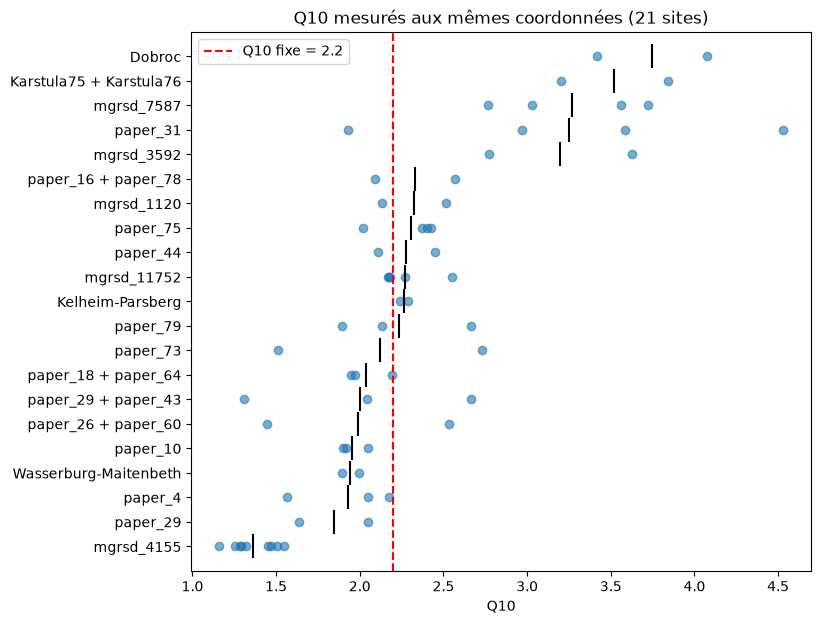

In [11]:
# Graphique : une ligne par groupe, points = mesures de Q10, trait noir = moyenne du groupe
rang = doublons.groupe.map({g: i for i, g in enumerate(moyennes.index)})
plt.figure(figsize=(8, 7))
plt.scatter(doublons.Q10, rang, alpha=0.6)
plt.scatter(moyennes, range(len(moyennes)), marker="|", s=300, c="k")
plt.axvline(2.2, ls="--", c="r", label="Q10 fixe = 2.2")
plt.yticks(range(len(moyennes)), noms)
plt.xlabel("Q10"); plt.title("Q10 mesurés aux mêmes coordonnées (21 sites)"); plt.legend()
plt.show()

**Constat :** l'étalement varie beaucoup d'un site à l'autre. Il est faible pour `mgrsd_4155` (9 parcelles, Q10 entre 1.16 et 1.55) et très fort pour `paper_31` (Irlande, Q10 entre 1.93 et 4.53).

### Étape 4 — Conséquence 1 : une erreur minimale impossible à éliminer

**Objectif :** estimer l'erreur que ferait quand même un modèle *parfait*.

**Raisonnement :** à l'intérieur d'un groupe, l'écart de chaque mesure à la moyenne du groupe ne peut pas être expliqué par nos variables. L'écart-type de ces écarts (écart-type **intra-site**) mesure ce bruit « local ». On le compare à l'écart-type total de Q10.

In [12]:
# Écart de chaque mesure à la moyenne de son groupe
ecart = doublons.Q10 - doublons.groupby("groupe").Q10.transform("mean")

In [13]:
# Écart-type intra-site (corrigé du nombre de groupes) comparé à l'écart-type total de Q10
sd_intra = (ecart.pow(2).sum() / (len(doublons) - doublons.groupe.nunique())) ** 0.5
print(f"Écart-type intra-site : {sd_intra:.2f} | écart-type total : {df.Q10.std():.2f}")

Écart-type intra-site : 0.45 | écart-type total : 0.96


**Constat :** ≈ 0.45 contre ≈ 0.96. Même un modèle parfait, qui connaîtrait la vraie moyenne de chaque site, ferait une erreur typique d'environ 0.45 sur une mesure isolée. Il expliquerait donc au mieux ≈ 78 % de la variance de Q10 (1 − 0.45² / 0.96²).

C'est un ordre de grandeur : il est estimé sur 21 sites seulement et suppose que la variabilité locale est similaire partout.

### Étape 5 — Conséquence 2 : une validation croisée aléatoire est trop optimiste

**Objectif :** montrer pourquoi la validation croisée doit être groupée.

**Raisonnement :** si on répartit les lignes au hasard, une parcelle d'un site peut se retrouver dans l'entraînement et sa « jumelle » dans le test. Le modèle a alors déjà vu l'entrée exacte du test : le score mesure en partie de la **mémoire**, et non la capacité à prédire un lieu nouveau, qui est justement notre objectif.

On compare deux découpages en 5 plis, répétés sur 10 tirages, avec une forêt aléatoire (utilisée ici uniquement comme exemple) :
- **aléatoire** (`KFold`) : les lignes sont réparties au hasard ;
- **groupé** (`GroupKFold`) : toutes les lignes d'un même site restent ensemble.

In [14]:
# Imports : modèle d'exemple et outils de validation croisée
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

In [15]:
# RMSE moyen en validation croisée pour un découpage donné (groups : site de chaque ligne, si découpage groupé)
def rmse_cv(cv, groups=None):
    return -cross_val_score(RandomForestRegressor(random_state=0), df[X_cols], df.Q10, cv=cv, groups=groups, scoring="neg_root_mean_squared_error").mean()

In [16]:
# RMSE sur 10 tirages : découpage aléatoire, puis découpage groupé par site
rmse_aleatoire = [rmse_cv(KFold(5, shuffle=True, random_state=s)) for s in range(10)]
rmse_groupe = [rmse_cv(GroupKFold(5, shuffle=True, random_state=s), df.groupe) for s in range(10)]
print(f"Aléatoire : {sum(rmse_aleatoire) / 10:.3f} | Groupé : {sum(rmse_groupe) / 10:.3f}")

Aléatoire : 0.904 | Groupé : 0.935


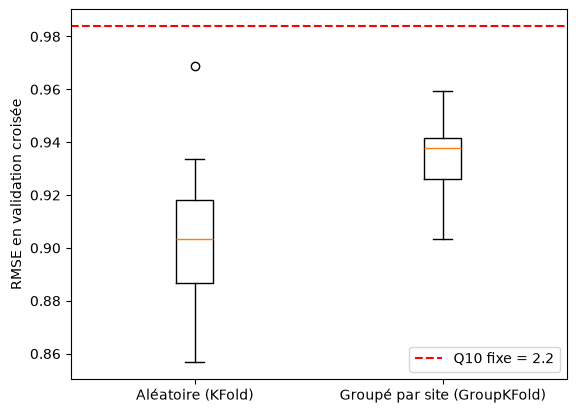

In [17]:
# Comparaison des deux découpages, avec l'erreur de la constante 2.2 comme repère
plt.boxplot([rmse_aleatoire, rmse_groupe], tick_labels=["Aléatoire (KFold)", "Groupé par site (GroupKFold)"])
plt.axhline(((df.Q10 - 2.2) ** 2).mean() ** 0.5, ls="--", c="r", label="Q10 fixe = 2.2")
plt.ylabel("RMSE en validation croisée"); plt.legend()
plt.show()

**Constat :** en moyenne, le découpage aléatoire donne une erreur plus faible (≈ 0.90 contre ≈ 0.93) : il **surestime** la qualité du modèle. L'écart reste modeste et varie selon le tirage, car seules 36 % des lignes sont concernées. Il suffit pourtant à fausser une comparaison entre modèles proches.

À noter : en découpage groupé, cette forêt aléatoire ne fait qu'un peu mieux que 2.2 avec ces 4 variables. C'est un premier aperçu de la difficulté du problème, qui sera étudié plus tard.

## Résumé de la partie A

- **Ce que cela veut dire :** 63 lignes (21 sites) partagent exactement les mêmes variables explicatives, car elles ont été mesurées au même endroit (parcelles, peuplements ou publications différentes). Leurs Q10 diffèrent pour des raisons locales, invisibles sur des cartes mondiales.
- **Conséquence 1 :** une erreur minimale d'environ 0.45 est impossible à éliminer avec ce type de variables.
- **Conséquence 2 :** la validation croisée doit être **groupée**, au minimum par site, et idéalement par zone géographique, car deux sites voisins se ressemblent aussi.
- **Décision (validée) :** agréger en une ligne par site (Q10 moyen) → `data/dataset_v2.csv`, créé dans `00_preparation_donnees.ipynb` (étape 4). Les parties suivantes de l'EDA utiliseront cette version.